# 14. Optimización multiobjetivo

Muchas decisiones persiguen varios objetivos que se contraponen, y entonces ya no existe una única solución mejor que todas las demás. La optimización multiobjetivo busca el conjunto de soluciones en las que no se puede mejorar un objetivo sin empeorar otro, el llamado frente de Pareto, y deja la elección final a quien decide. Este capítulo trabaja con un solo problema, la selección de un portafolio de inversión que maximice el rendimiento esperado y minimice el riesgo, y lo resuelve con dos algoritmos evolutivos multiobjetivo. El primero es NSGA-II (*Non-dominated Sorting Genetic Algorithm II*), que ordena la población por frentes de no dominancia y desempata con la distancia de apiñamiento (*crowding distance*). El segundo es SPEA2 (*Strength Pareto Evolutionary Algorithm 2*), que asigna a cada solución una fuerza según cuántas domina y guarda las no dominadas en un archivo externo. Al final se comparan los dos frentes sobre los mismos datos.

In [1]:
import random
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

## Dominancia de Pareto y frente de Pareto

Supongamos que todos los objetivos se minimizan, $f_1(x), \dots, f_M(x)$. Una solución $x$ domina a otra solución $y$, y se escribe $x \prec y$, cuando $x$ no es peor que $y$ en ningún objetivo y es estrictamente mejor en al menos uno:

$$
x \prec y \iff f_m(x) \le f_m(y) \ \ \forall m \in \{1,\dots,M\} \quad \text{y} \quad \exists\, m : f_m(x) < f_m(y).
$$

Una solución es no dominada dentro de un conjunto si ninguna otra del conjunto la domina. El conjunto de soluciones no dominadas de todo el espacio factible se llama conjunto óptimo de Pareto, y su imagen en el espacio de los objetivos es el frente de Pareto. Un algoritmo multiobjetivo entrega una aproximación de ese frente, y su calidad se juzga por dos propiedades a la vez, qué tan cerca está del frente verdadero (convergencia) y qué tan bien lo cubre de un extremo a otro (diversidad). NSGA-II y SPEA2 difieren sobre todo en cómo atienden la segunda.

Cuando un objetivo se maximiza, se convierte en minimización cambiándole el signo. Así lo hacen los dos códigos de este capítulo con el rendimiento del portafolio.

## El problema de selección de portafolio

Hay $n$ activos con rendimientos esperados $\mu_i$ y matriz de covarianza $\Sigma$. Una solución es el vector de pesos $w = (w_1,\dots,w_n)$, con $w_i \ge 0$ y $\sum_i w_i = 1$, que indica qué fracción del capital va a cada activo. El rendimiento esperado y el riesgo, medido como la varianza del portafolio, son

$$
R(w) = \sum_{i=1}^{n} w_i\,\mu_i, \qquad V(w) = w^\top \Sigma\, w,
$$

y el problema consiste en maximizar $R(w)$ y minimizar $V(w)$ al mismo tiempo. Los dos algoritmos trabajan con el vector de objetivos $\big(-R(w),\, V(w)\big)$, ambos a minimizar.

Los datos son simulados. Con cinco activos, los rendimientos se toman uniformes entre 0,05 y 0,25, y la covarianza se construye como $AA^\top$ a partir de una matriz aleatoria $A$, lo que garantiza que sea semidefinida positiva; a la diagonal se le suma 0,001 para evitar que sea singular. La semilla es la misma para los dos algoritmos, de modo que ambos resuelven exactamente la misma instancia.

In [2]:
# ---------------------------------------------------------------------------
# 1. DEFINICIÓN DEL PROBLEMA: SELECCIÓN DE PORTAFOLIO
# ---------------------------------------------------------------------------

# Datos simulados para los activos
NUM_ASSETS = 5
np.random.seed(42)  # Para reproducibilidad (la misma instancia para NSGA-II y SPEA2)
# Rendimientos esperados anuales (simulados)
expected_returns = np.random.uniform(0.05, 0.25, NUM_ASSETS)
# Matriz de covarianza (simulada)
# Se genera una matriz aleatoria y se asegura que sea semidefinida positiva
temp_cov = np.random.rand(NUM_ASSETS, NUM_ASSETS) * 0.05
covariance_matrix = np.dot(temp_cov, temp_cov.transpose())
# Añadir un pequeño valor a la diagonal para asegurar que no sea singular
# y mejorar la estabilidad numérica si los rendimientos son muy correlacionados
np.fill_diagonal(covariance_matrix, np.diag(covariance_matrix) + 0.001)


def calculate_portfolio_performance(weights, expected_returns, covariance_matrix):
    """
    Calcula el rendimiento esperado y el riesgo (varianza) de un portafolio.
    """
    portfolio_return = np.sum(weights * expected_returns)
    portfolio_variance = np.dot(weights.T, np.dot(covariance_matrix, weights))
    return portfolio_return, portfolio_variance


print("Problema de Selección de Portafolios Multiobjetivo")
print(f"Número de activos: {NUM_ASSETS}")
print(f"Rendimientos Esperados (anual): {np.round(expected_returns, 4)}")
print(f"Matriz de Covarianza:\n{np.round(covariance_matrix, 4)}")

Problema de Selección de Portafolios Multiobjetivo
Número de activos: 5
Rendimientos Esperados (anual): [0.1249 0.2401 0.1964 0.1697 0.0812]
Matriz de Covarianza:
[[0.0051 0.0026 0.0024 0.0022 0.0024]
 [0.0026 0.0053 0.0022 0.0014 0.0019]
 [0.0024 0.0022 0.0027 0.0015 0.0019]
 [0.0022 0.0014 0.0015 0.0031 0.0022]
 [0.0024 0.0019 0.0019 0.0022 0.0042]]


## NSGA-II

NSGA-II es un algoritmo genético con dos piezas propias. La primera es el ordenamiento rápido no dominado (*fast non-dominated sort*), que reparte la población en frentes sucesivos $F_1, F_2, \dots$. El primero reúne las soluciones no dominadas, el segundo las que solo están dominadas por soluciones de $F_1$, y así sucesivamente. El índice del frente es el rango de la solución, y un rango menor es mejor. La segunda pieza es la distancia de apiñamiento, que mide cuán aislada está una solución dentro de su frente y sirve para preferir las soluciones de las zonas menos pobladas, lo que mantiene la diversidad.

### Representación e individuo

Cada individuo guarda un vector de pesos que suma 1. Si no se le dan pesos, los genera uniformes en $[0,1]$ y los normaliza. El método `evaluate` calcula $\big(-R(w), V(w)\big)$ y el método `dominates` implementa la definición de dominancia de la sección anterior.

In [3]:
# ---------------------------------------------------------------------------
# 2. COMPONENTES DE LA METAHEURÍSTICA (NSGA-II)
# ---------------------------------------------------------------------------

class Individual:
    """
    Representa una solución (un portafolio) en la población.
    """
    def __init__(self, weights=None):
        if weights is None:
            # Generar pesos aleatorios que sumen 1
            raw_weights = np.random.rand(NUM_ASSETS)
            self.weights = raw_weights / np.sum(raw_weights)
        else:
            self.weights = np.array(weights)

        self.objectives = []  # [Rendimiento, Riesgo] -> Maximizar Rendimiento, Minimizar Riesgo
        self.rank = 0         # Rango de no dominancia
        self.crowding_distance = 0.0
        self.dominated_solutions = set() # Soluciones que este individuo domina
        self.domination_count = 0      # Número de soluciones que dominan a este individuo

    def evaluate(self):
        """Calcula los valores de los objetivos para este individuo."""
        portfolio_return, portfolio_variance = calculate_portfolio_performance(
            self.weights, expected_returns, covariance_matrix
        )
        # Queremos MAXIMIZAR el rendimiento y MINIMIZAR el riesgo.
        # NSGA-II usualmente asume minimización para todos los objetivos.
        # Por lo tanto, convertimos la maximización del rendimiento en minimización de -rendimiento.
        self.objectives = [-portfolio_return, portfolio_variance]

    def dominates(self, other_individual):
        """
        Verifica si este individuo domina a otro_individuo.
        Asume minimización para ambos objetivos.
        """
        better_in_at_least_one = False
        for i in range(len(self.objectives)):
            if self.objectives[i] < other_individual.objectives[i]:
                better_in_at_least_one = True
            elif self.objectives[i] > other_individual.objectives[i]:
                return False # No domina si es peor en algún objetivo
        return better_in_at_least_one

### Ordenamiento rápido no dominado

Para cada solución $p$ la función calcula dos cosas, el conjunto $S_p$ de soluciones que $p$ domina y el contador $n_p$ de soluciones que dominan a $p$. Las soluciones con $n_p = 0$ forman el primer frente. Luego, para cada $p$ del frente actual y cada $q \in S_p$, se descuenta una unidad de $n_q$; las soluciones cuyo contador llega a cero pasan al frente siguiente. El proceso se repite hasta que no quedan soluciones por asignar. En el código el primer frente tiene rango 0.

In [4]:
def fast_non_dominated_sort(population):
    """
    Realiza el ordenamiento rápido no dominado de la población.
    Devuelve una lista de frentes, donde cada frente es una lista de individuos.
    """
    fronts = [[]]
    for p in population:
        p.dominated_solutions = set()
        p.domination_count = 0
        for q in population:
            if p == q:
                continue
            if p.dominates(q):
                p.dominated_solutions.add(q)
            elif q.dominates(p):
                p.domination_count += 1
        if p.domination_count == 0:
            p.rank = 0 # Rango 0 para el primer frente (más tarde se ajusta a 1, 2, ...)
            fronts[0].append(p)

    i = 0
    while fronts[i]:
        next_front = []
        for p in fronts[i]:
            for q in p.dominated_solutions:
                q.domination_count -= 1
                if q.domination_count == 0:
                    q.rank = i + 1
                    next_front.append(q)
        i += 1
        if next_front:
            fronts.append(next_front)
        else:
            break
    return fronts

Para ver qué produce esta función, evaluamos 200 portafolios aleatorios y coloreamos los primeros frentes. Los puntos del primer frente forman el borde superior izquierdo de la nube (más rendimiento con menos riesgo), y cada frente siguiente queda detrás del anterior.

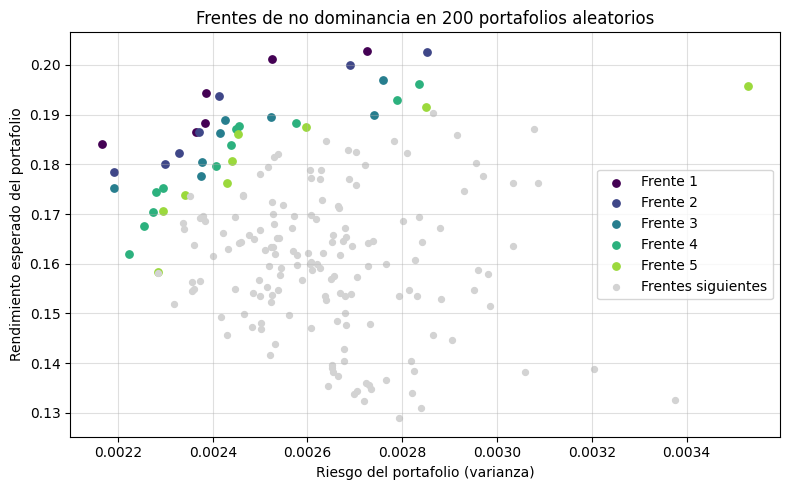

Número de frentes en la muestra: 28


In [5]:
random.seed(42)
np.random.seed(42)

muestra = [Individual() for _ in range(200)]
for ind in muestra:
    ind.evaluate()
frentes_muestra = fast_non_dominated_sort(muestra)

fig, ax = plt.subplots(figsize=(8, 5))
colores = plt.cm.viridis(np.linspace(0, 0.85, 5))
for r, frente in enumerate(frentes_muestra[:5]):
    ax.scatter([ind.objectives[1] for ind in frente], [-ind.objectives[0] for ind in frente],
               color=colores[r], s=28, label=f'Frente {r + 1}')
resto = [ind for frente in frentes_muestra[5:] for ind in frente]
ax.scatter([ind.objectives[1] for ind in resto], [-ind.objectives[0] for ind in resto],
           color='lightgray', s=18, label='Frentes siguientes')
ax.set_xlabel('Riesgo del portafolio (varianza)')
ax.set_ylabel('Rendimiento esperado del portafolio')
ax.set_title('Frentes de no dominancia en 200 portafolios aleatorios')
ax.legend()
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()
print(f"Número de frentes en la muestra: {len(frentes_muestra)}")

### Distancia de apiñamiento

Dentro de un frente con $L$ soluciones, para cada objetivo $m$ se ordenan las soluciones según $f_m$. Las dos soluciones de los extremos reciben distancia infinita, para que nunca se pierdan, y cada solución intermedia $i$ acumula la diferencia normalizada entre sus vecinas:

$$
d_i \;=\; \sum_{m=1}^{M} \frac{f_m^{(i+1)} - f_m^{(i-1)}}{f_m^{\max} - f_m^{\min}},
$$

donde $f_m^{(i\pm 1)}$ son los valores de las soluciones vecinas en el orden según $f_m$, y $f_m^{\max}$, $f_m^{\min}$ son los valores extremos del frente. Una distancia grande indica una solución rodeada de pocas vecinas. Si todos los valores del objetivo coinciden, el código usa 1 como escala para no dividir por cero.

In [6]:
def calculate_crowding_distance(front):
    """
    Calcula la distancia de crowding para cada individuo en un frente.
    """
    if not front:
        return

    num_objectives = len(front[0].objectives)
    front_size = len(front)

    for p in front:
        p.crowding_distance = 0.0

    for m in range(num_objectives):
        # Ordenar el frente por el objetivo m
        front.sort(key=lambda ind: ind.objectives[m])

        # Asignar distancia infinita a las soluciones frontera
        front[0].crowding_distance = float('inf')
        front[front_size - 1].crowding_distance = float('inf')

        if front_size > 2:
            min_obj_val = front[0].objectives[m]
            max_obj_val = front[front_size - 1].objectives[m]
            scale = max_obj_val - min_obj_val
            if scale == 0: # Evitar división por cero si todos los valores del objetivo son iguales
                scale = 1.0 # O asignar una distancia pequeña o manejar de otra forma

            for i in range(1, front_size - 1):
                if front[i].crowding_distance != float('inf'): # No sobrescribir si ya es infinito
                    distance = front[i+1].objectives[m] - front[i-1].objectives[m]
                    front[i].crowding_distance += distance / scale

### Selección, cruce y mutación

La selección es un torneo binario con el operador de comparación por apiñamiento, según el cual gana el individuo de menor rango y, si los dos empatan en rango, el de mayor distancia de apiñamiento.

El cruce es aritmético. Con probabilidad $p_c$ se toma $\alpha \sim U(0,1)$ y se generan dos hijos como combinaciones convexas de los padres,

$$
w^{(1)} = \alpha\, w^{p_1} + (1-\alpha)\, w^{p_2}, \qquad w^{(2)} = (1-\alpha)\, w^{p_1} + \alpha\, w^{p_2};
$$

con probabilidad $1-p_c$ los hijos son copias de los padres. La mutación recorre los pesos y, con probabilidad $p_m$ por peso, le suma un ruido gaussiano $\mathcal{N}(0, \sigma^2)$. Después del cruce y de la mutación, los pesos se recortan al intervalo $[0,1]$ y se normalizan para que sumen 1, de modo que el hijo siempre es un portafolio válido.

In [7]:
def tournament_selection(population, k=2):
    """
    Selección por torneo. Elige k individuos y devuelve el mejor.
    Mejor es: menor rango, o igual rango y mayor distancia de crowding.
    """
    selected_tournament = random.sample(population, k)
    best = selected_tournament[0]
    for i in range(1, k):
        ind = selected_tournament[i]
        if ind.rank < best.rank:
            best = ind
        elif ind.rank == best.rank:
            if ind.crowding_distance > best.crowding_distance:
                best = ind
    return best

def crossover(parent1, parent2, cr=0.9):
    """
    Operador de cruce aritmético simple.
    Normaliza los pesos para que sumen 1.
    """
    if random.random() > cr:
        return Individual(parent1.weights.copy()), Individual(parent2.weights.copy())

    alpha = random.random()
    weights1 = alpha * parent1.weights + (1 - alpha) * parent2.weights
    weights2 = (1 - alpha) * parent1.weights + alpha * parent2.weights

    # Normalizar para asegurar que los pesos sumen 1 y sean no negativos
    child1_weights = np.clip(weights1, 0, 1)
    child1_weights /= np.sum(child1_weights) if np.sum(child1_weights) > 0 else 1

    child2_weights = np.clip(weights2, 0, 1)
    child2_weights /= np.sum(child2_weights) if np.sum(child2_weights) > 0 else 1

    return Individual(child1_weights), Individual(child2_weights)


def mutate(individual, mr=0.1, mutation_strength=0.1):
    """
    Operador de mutación: añade pequeño ruido gaussiano a algunos pesos.
    Normaliza los pesos para que sumen 1.
    """
    mutated_weights = individual.weights.copy()
    for i in range(NUM_ASSETS):
        if random.random() < mr:
            mutated_weights[i] += random.gauss(0, mutation_strength)

    # Asegurar que los pesos estén entre 0 y 1 y sumen 1
    mutated_weights = np.clip(mutated_weights, 0, 1)
    sum_weights = np.sum(mutated_weights)
    if sum_weights > 0:
        mutated_weights /= sum_weights
    else: # Si todos los pesos se volvieron cero, re-inicializar aleatoriamente
        raw_weights = np.random.rand(NUM_ASSETS)
        mutated_weights = raw_weights / np.sum(raw_weights)

    individual.weights = mutated_weights
    # La evaluación se hará después de crear toda la población de descendientes

### El ciclo de NSGA-II

En cada generación $t$, a partir de la población $P_t$ de tamaño $N$ se crean $N$ descendientes $Q_t$ con selección, cruce y mutación. Las dos poblaciones se unen en $R_t = P_t \cup Q_t$, de tamaño $2N$, y $R_t$ se ordena por frentes. La nueva población $P_{t+1}$ se llena con frentes completos, en orden, mientras quepan. El primer frente que no cabe entero se ordena por distancia de apiñamiento de mayor a menor y aporta solo las soluciones necesarias para completar $N$. Como padres y descendientes compiten juntos, una buena solución solo sale de la población si aparecen otras que la superan, y en eso consiste el elitismo de NSGA-II. Al terminar, el algoritmo devuelve el primer frente de la última población.

In [8]:
# ---------------------------------------------------------------------------
# 3. BUCLE PRINCIPAL DE NSGA-II
# ---------------------------------------------------------------------------

def nsga_ii(pop_size, num_generations, crossover_rate, mutation_rate, mutation_strength_val):
    """
    Algoritmo NSGA-II principal.
    """
    start_time = time.time()

    # --- Inicialización ---
    # P_t: Población actual
    population = [Individual() for _ in range(pop_size)]
    for ind in population:
        ind.evaluate() # Evaluar objetivos

    # Ordenar y calcular distancia de crowding para la población inicial
    fronts = fast_non_dominated_sort(population)
    for front in fronts:
        calculate_crowding_distance(front)

    # --- Bucle de Generaciones ---
    print("Iniciando NSGA-II...")
    for gen in range(num_generations):
        if (gen + 1) % 10 == 0 or gen == 0:
            print(f"Generación {gen + 1}/{num_generations}")

        # --- Creación de la Población de Descendientes (Q_t) ---
        offspring_population = []
        while len(offspring_population) < pop_size:
            parent1 = tournament_selection(population)
            parent2 = tournament_selection(population)
            child1, child2 = crossover(parent1, parent2, cr=crossover_rate)
            mutate(child1, mr=mutation_rate, mutation_strength=mutation_strength_val)
            mutate(child2, mr=mutation_rate, mutation_strength=mutation_strength_val)
            offspring_population.append(child1)
            if len(offspring_population) < pop_size:
                offspring_population.append(child2)

        for ind in offspring_population:
            ind.evaluate() # Evaluar nuevos individuos

        # --- Combinar Población Actual y Descendientes (R_t = P_t U Q_t) ---
        combined_population = population + offspring_population

        # --- Selección para la Siguiente Generación (P_{t+1}) ---
        # Aplicar Fast Non-Dominated Sort a R_t
        fronts = fast_non_dominated_sort(combined_population)

        new_population = []
        for front in fronts:
            if not front: continue # Si un frente está vacío
            calculate_crowding_distance(front) # Calcular crowding para el frente actual
            if len(new_population) + len(front) <= pop_size:
                new_population.extend(front)
            else:
                # Si el frente no cabe completo, ordenarlo por crowding distance
                # y tomar los individuos con mayor distancia
                front.sort(key=lambda ind: ind.crowding_distance, reverse=True)
                remaining_space = pop_size - len(new_population)
                new_population.extend(front[:remaining_space])
                break
        population = new_population

    # --- Fin del Algoritmo ---
    end_time = time.time()
    print(f"NSGA-II finalizado en {end_time - start_time:.2f} segundos.")

    # El Frente de Pareto final es el primer frente de la última población
    final_front = fast_non_dominated_sort(population)[0]
    return final_front

### Ejecución de NSGA-II

Se usa una población de 100 individuos durante 100 generaciones, con probabilidad de cruce 0,9, probabilidad de mutación por peso 0,1 y desviación estándar de la mutación 0,1.

Iniciando NSGA-II...
Generación 1/100
Generación 10/100


Generación 20/100
Generación 30/100


Generación 40/100
Generación 50/100


Generación 60/100
Generación 70/100


Generación 80/100
Generación 90/100


Generación 100/100
NSGA-II finalizado en 1.88 segundos.

Frente de Pareto encontrado (contiene 100 soluciones):


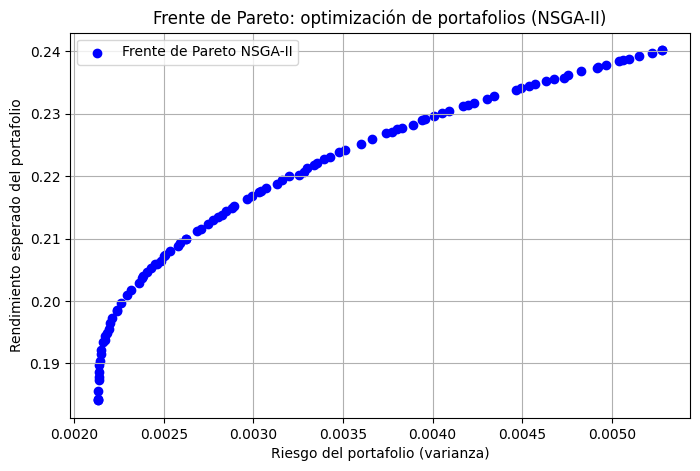


Extensión del Frente de Pareto:
  Rango de Riesgo: [0.0021 - 0.0053]
  Rango de Rendimiento: [0.1841 - 0.2401]


In [9]:
# ---------------------------------------------------------------------------
# 4. EJECUCIÓN Y SALIDAS
# ---------------------------------------------------------------------------
random.seed(42)
np.random.seed(42)

# Parámetros de la metaheurística
POPULATION_SIZE = 100
NUM_GENERATIONS = 100 # Aumentar para mejores resultados, pero más tiempo
CROSSOVER_RATE = 0.9
MUTATION_RATE = 0.1 # Probabilidad de mutar cada gen (peso)
MUTATION_STRENGTH = 0.1 # Desviación estándar para la mutación gaussiana

final_pareto_front = nsga_ii(
    POPULATION_SIZE,
    NUM_GENERATIONS,
    CROSSOVER_RATE,
    MUTATION_RATE,
    MUTATION_STRENGTH
)

print(f"\nFrente de Pareto encontrado (contiene {len(final_pareto_front)} soluciones):")
# Extraer objetivos para graficar y mostrar (recordar que el rendimiento fue negado)
pareto_returns = []
pareto_risks = []

for i, ind in enumerate(final_pareto_front):
    actual_return = -ind.objectives[0] # Revertir la negación
    risk = ind.objectives[1]
    pareto_returns.append(actual_return)
    pareto_risks.append(risk)

# --- Visualización del Frente de Pareto ---
plt.figure(figsize=(8, 5))
plt.scatter(pareto_risks, pareto_returns, c='blue', marker='o', label='Frente de Pareto NSGA-II')
plt.title('Frente de Pareto: optimización de portafolios (NSGA-II)')
plt.xlabel('Riesgo del portafolio (varianza)')
plt.ylabel('Rendimiento esperado del portafolio')
plt.legend()
plt.grid(True)
plt.show()

# --- Salidas de Rendimiento del Algoritmo ---
# Extensión del frente (rango de riesgo y rendimiento):
if final_pareto_front:
    min_risk_on_front = min(pareto_risks)
    max_risk_on_front = max(pareto_risks)
    min_return_on_front = min(pareto_returns)
    max_return_on_front = max(pareto_returns)
    print(f"\nExtensión del Frente de Pareto:")
    print(f"  Rango de Riesgo: [{min_risk_on_front:.4f} - {max_risk_on_front:.4f}]")
    print(f"  Rango de Rendimiento: [{min_return_on_front:.4f} - {max_return_on_front:.4f}]")

Las soluciones del frente se reparten a lo largo de una curva creciente y cóncava. Para ganar rendimiento hay que aceptar más varianza, y cada unidad adicional de rendimiento cuesta más riesgo a medida que nos movemos hacia la derecha. El extremo izquierdo corresponde a los portafolios de menor varianza. En el extremo derecho el rendimiento máximo del frente coincide con el rendimiento esperado del segundo activo, el más alto de los cinco, lo que indica que allí casi todo el capital va a ese activo. Elegir un punto de esa curva ya no es tarea del algoritmo, sino de quien decide según su aversión al riesgo.

## SPEA2

SPEA2 atiende la convergencia y la diversidad con otras herramientas. Cada generación trabaja con la población $P_t$, de tamaño $N$, y con un archivo externo $\bar{A}_t$, de tamaño máximo $\bar{N}$, que guarda las mejores soluciones no dominadas encontradas hasta el momento. Los padres de la siguiente generación salen del archivo.

### Fuerza y aptitud bruta

Sobre el conjunto combinado $P_t \cup \bar{A}_t$, la fuerza (*strength*) de una solución es el número de soluciones que domina,

$$
S(i) = \big|\{\, j \in P_t \cup \bar{A}_t : i \prec j \,\}\big|,
$$

y su aptitud bruta (*raw fitness*) suma las fuerzas de las soluciones que la dominan,

$$
R(i) = \sum_{j \in P_t \cup \bar{A}_t,\ j \prec i} S(j).
$$

Una solución no dominada tiene $R(i) = 0$; cuanto mayor es $R(i)$, más dominada está y por soluciones más fuertes.

### Densidad y aptitud

Varias soluciones pueden tener la misma aptitud bruta, en particular todas las no dominadas, que tienen $R(i) = 0$. Para distinguirlas se estima la densidad alrededor de cada una. Con $k = \lfloor \sqrt{N + |\bar{A}_t|} \rfloor$ y $\sigma_i^k$ la distancia euclidiana, en el espacio de los objetivos, de la solución $i$ a su $k$-ésimo vecino más cercano dentro de $P_t \cup \bar{A}_t$, la densidad es

$$
D(i) = \frac{1}{\sigma_i^k + 2}.
$$

Como $\sigma_i^k \ge 0$, la densidad es menor que $1/2$, y una solución más aislada tiene una densidad menor. La aptitud final es

$$
F(i) = R(i) + D(i),
$$

que se minimiza. Como $D(i) < 1$, una solución no dominada tiene $F(i) < 1$ y siempre es preferible a una dominada; entre dos soluciones con la misma aptitud bruta, se prefiere la más aislada.

El rendimiento esperado y la varianza tienen escalas distintas, de modo que la distancia euclidiana sin más dependería casi solo del objetivo de mayor rango. Por eso el código escala cada objetivo al intervalo $[0,1]$, con el mínimo y el máximo de $P_t \cup \bar{A}_t$, antes de calcular las distancias.

### Actualización del archivo

El nuevo archivo $\bar{A}_{t+1}$ recibe todas las soluciones no dominadas de $P_t \cup \bar{A}_t$. Si son menos de $\bar{N}$, se completa con las soluciones dominadas de menor aptitud $F(i)$. Si son más, se aplica el truncamiento, que retira una solución a la vez. En cada paso retira la que está más cerca de su vecina más cercana dentro del archivo; si hay empate, compara la distancia a la segunda vecina, y así sucesivamente. Retirar de una en una, y recalcular las distancias después de cada retiro, evita abrir huecos en el frente, porque de dos soluciones muy cercanas solo sale una.

### Reproducción

Los padres se eligen del archivo mediante torneos binarios en los que gana la solución de menor aptitud $F(i)$. El cruce aritmético es el mismo de NSGA-II. La mutación cambia de forma. Con probabilidad $p_m$ por individuo, se suma a todo el vector de pesos un ruido $\mathcal{N}(0,\sigma^2 I)$ y luego se recorta y normaliza. Al terminar, el algoritmo devuelve las soluciones no dominadas del archivo.

Los individuos de SPEA2 tienen la misma representación y la misma regla de dominancia que los de NSGA-II, más los atributos de fuerza, aptitud bruta, densidad y aptitud final.

In [10]:
# ---------------------------------------------------------------------------
# 2. IMPLEMENTACIÓN SPEA2
# ---------------------------------------------------------------------------

class SPEA2Individual:
    """
    Clase que representa un individuo en el algoritmo SPEA2.
    Cada individuo representa una posible solución (distribución de pesos del portafolio).
    """

    def __init__(self, weights=None):
        """
        Inicializa un individuo con pesos aleatorios o predefinidos.

        Args:
            weights (np.array, optional): Pesos predefinidos del portafolio
        """
        if weights is None:
            raw_weights = np.random.rand(NUM_ASSETS)
            self.weights = raw_weights / np.sum(raw_weights)
        else:
            self.weights = np.array(weights)
        self.objectives = []  # [rendimiento, riesgo]
        self.strength = 0     # Fuerza de dominancia
        self.raw_fitness = 0  # Fitness bruto
        self.density = 0.0    # Densidad de soluciones cercanas
        self.fitness = 0.0    # Fitness final

    def evaluate(self):
        """
        Evalúa los objetivos del individuo:
        - Maximizar rendimiento (minimizar -rendimiento)
        - Minimizar riesgo (varianza)
        """
        portfolio_return, portfolio_variance = calculate_portfolio_performance(
            self.weights, expected_returns, covariance_matrix
        )
        self.objectives = [-portfolio_return, portfolio_variance]

    def dominates(self, other):
        """
        Determina si este individuo domina a otro según el criterio de Pareto.

        Args:
            other (SPEA2Individual): Otro individuo a comparar

        Returns:
            bool: True si este individuo domina al otro
        """
        better_in_one = False
        for i in range(len(self.objectives)):
            if self.objectives[i] < other.objectives[i]:
                better_in_one = True
            elif self.objectives[i] > other.objectives[i]:
                return False
        return better_in_one

In [11]:
def spea2(pop_size=80, archive_size=20, generations=100, cr=0.9, mr=0.1, ms=0.1):
    """
    Implementación del algoritmo SPEA2 para optimización multiobjetivo.

    Args:
        pop_size (int): Tamaño de la población
        archive_size (int): Tamaño del archivo de soluciones no dominadas
        generations (int): Número de generaciones
        cr (float): Probabilidad de cruce
        mr (float): Probabilidad de mutación
        ms (float): Magnitud de la mutación

    Returns:
        list: Archivo final con las soluciones no dominadas (frente de Pareto)
    """
    # Inicialización
    population = [SPEA2Individual() for _ in range(pop_size)]
    archive = []

    for gen in range(generations):
        # Evaluar población
        for ind in population:
            ind.evaluate()

        # Calcular fitness sobre la población y el archivo
        combined = population + archive
        for ind in combined:
            ind.strength = sum(1 for other in combined if ind.dominates(other))
        for ind in combined:
            ind.raw_fitness = sum(other.strength for other in combined if other.dominates(ind))

        # Densidad: distancia al k-ésimo vecino con los objetivos escalados a [0, 1]
        objectives = np.array([ind.objectives for ind in combined])
        rango = objectives.max(axis=0) - objectives.min(axis=0)
        rango[rango == 0] = 1.0
        escalados = (objectives - objectives.min(axis=0)) / rango
        distances = cdist(escalados, escalados)
        k = int(np.sqrt(len(combined)))
        for i, ind in enumerate(combined):
            ind.density = 1.0 / (np.sort(distances[i])[k] + 2.0)
            ind.fitness = ind.raw_fitness + ind.density

        # Actualizar archivo con soluciones no dominadas
        indices = [i for i, ind in enumerate(combined) if ind.raw_fitness == 0]

        if len(indices) < archive_size:
            # Completar el archivo con las mejores soluciones dominadas según el fitness
            dominadas = sorted((i for i, ind in enumerate(combined) if ind.raw_fitness > 0),
                               key=lambda i: combined[i].fitness)
            indices += dominadas[:archive_size - len(indices)]
        else:
            # Truncamiento: retirar una a una la solución más cercana a sus vecinas
            while len(indices) > archive_size:
                sub = distances[np.ix_(indices, indices)]
                np.fill_diagonal(sub, np.inf)
                vecinos = np.sort(sub, axis=1)  # Distancias a la vecina más cercana, a la segunda, ...
                peor = min(range(len(indices)), key=lambda a: tuple(vecinos[a]))
                indices.pop(peor)

        archive = [combined[i] for i in indices]

        # Selección y reproducción (los padres salen del archivo)
        mating_pool = archive
        next_pop = []

        while len(next_pop) < pop_size:
            # Selección por torneo
            p1 = random.choice(mating_pool)
            p2 = random.choice(mating_pool)
            parent1 = p1 if p1.fitness < p2.fitness else p2

            p1 = random.choice(mating_pool)
            p2 = random.choice(mating_pool)
            parent2 = p1 if p1.fitness < p2.fitness else p2

            # Cruce aritmético
            if random.random() < cr:
                alpha = random.random()
                child1_weights = alpha * parent1.weights + (1 - alpha) * parent2.weights
                child2_weights = (1 - alpha) * parent1.weights + alpha * parent2.weights

                # Normalizar pesos
                child1_weights = np.clip(child1_weights, 0, 1)
                child1_weights /= np.sum(child1_weights)
                child2_weights = np.clip(child2_weights, 0, 1)
                child2_weights /= np.sum(child2_weights)

                child1 = SPEA2Individual(child1_weights)
                child2 = SPEA2Individual(child2_weights)
            else:
                child1 = SPEA2Individual(parent1.weights.copy())
                child2 = SPEA2Individual(parent2.weights.copy())

            # Mutación gaussiana
            for child in [child1, child2]:
                if random.random() < mr:
                    mutation = np.random.normal(0, ms, NUM_ASSETS)
                    child.weights = np.clip(child.weights + mutation, 0, 1)
                    child.weights /= np.sum(child.weights)

            next_pop.extend([child1, child2])

        population = next_pop[:pop_size]

    # Devolver solo las soluciones no dominadas del archivo
    return [ind for ind in archive if ind.raw_fitness == 0]

### Ejecución de SPEA2

Se usan los valores por omisión de la función: una población de 80 individuos, un archivo de 20, 100 generaciones, probabilidad de cruce 0,9, probabilidad de mutación por individuo 0,1 y desviación estándar 0,1.

SPEA2 finalizado en 0.83 segundos.


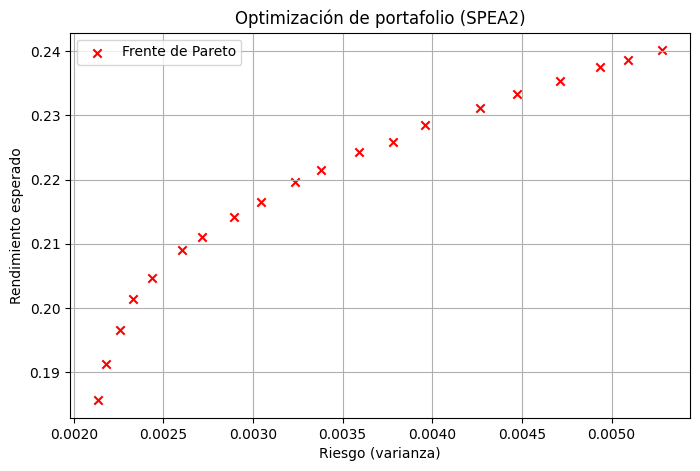


Frente de Pareto encontrado (20 soluciones):
Solución 1: Rendimiento=0.1856, Riesgo=0.0021, Pesos=[0.    0.116 0.443 0.395 0.046]
Solución 2: Rendimiento=0.1913, Riesgo=0.0022, Pesos=[0.    0.199 0.412 0.351 0.038]
Solución 3: Rendimiento=0.1966, Riesgo=0.0023, Pesos=[0.    0.269 0.389 0.315 0.028]
Solución 4: Rendimiento=0.2013, Riesgo=0.0023, Pesos=[0.    0.32  0.34  0.339 0.   ]
Solución 5: Rendimiento=0.2046, Riesgo=0.0024, Pesos=[0.005 0.359 0.375 0.258 0.002]
Solución 6: Rendimiento=0.2090, Riesgo=0.0026, Pesos=[0.    0.437 0.318 0.245 0.   ]
Solución 7: Rendimiento=0.2111, Riesgo=0.0027, Pesos=[0.    0.478 0.292 0.23  0.   ]
Solución 8: Rendimiento=0.2141, Riesgo=0.0029, Pesos=[0.004 0.526 0.284 0.184 0.001]
Solución 9: Rendimiento=0.2165, Riesgo=0.0030, Pesos=[0.004 0.572 0.252 0.171 0.001]
Solución 10: Rendimiento=0.2196, Riesgo=0.0032, Pesos=[0.    0.62  0.235 0.145 0.   ]
Solución 11: Rendimiento=0.2214, Riesgo=0.0034, Pesos=[0.002 0.653 0.221 0.124 0.001]
Solución 12: Rend

In [12]:
# ---------------------------------------------------------------------------
# 3. EJECUCIÓN Y VISUALIZACIÓN
# ---------------------------------------------------------------------------
random.seed(42)
np.random.seed(42)

inicio_spea2 = time.time()
pareto_front = spea2()
print(f"SPEA2 finalizado en {time.time() - inicio_spea2:.2f} segundos.")

# Visualizar resultados
if pareto_front:
    returns = [-ind.objectives[0] for ind in pareto_front]
    risks = [ind.objectives[1] for ind in pareto_front]

    plt.figure(figsize=(8, 5))
    plt.scatter(risks, returns, c='red', marker='x', label='Frente de Pareto')
    plt.title('Optimización de portafolio (SPEA2)')
    plt.xlabel('Riesgo (varianza)')
    plt.ylabel('Rendimiento esperado')
    plt.legend()
    plt.grid(True)
    plt.show()

    print(f"\nFrente de Pareto encontrado ({len(pareto_front)} soluciones):")
    for i, ind in enumerate(sorted(pareto_front, key=lambda ind: ind.objectives[1])):
        print(f"Solución {i+1}: Rendimiento={-ind.objectives[0]:.4f}, "
              f"Riesgo={ind.objectives[1]:.4f}, Pesos={np.round(ind.weights, 3)}")

El archivo final tiene 20 soluciones, el tamaño fijado para él, repartidas desde el portafolio de menor varianza hasta el que pone todo el capital en el segundo activo, el de mayor rendimiento esperado. La tabla, ordenada por riesgo, muestra cómo cambian los pesos a lo largo del frente. A medida que crece el rendimiento aumenta el peso del segundo activo y disminuyen los del tercero y el cuarto, mientras que el primero y el quinto, los de menor rendimiento esperado, casi no reciben capital. El truncamiento retira primero las soluciones más cercanas entre sí, de modo que el archivo no guarda copias de un mismo portafolio y los puntos quedan espaciados a lo largo de la curva.

## Comparación de los dos frentes

Los dos algoritmos resolvieron la misma instancia, con la misma semilla para los datos, de modo que sus frentes se pueden superponer en una sola figura. Para cada uno se muestran también el número de soluciones y la extensión del frente en riesgo y en rendimiento, las mismas medidas que imprime el código de NSGA-II.

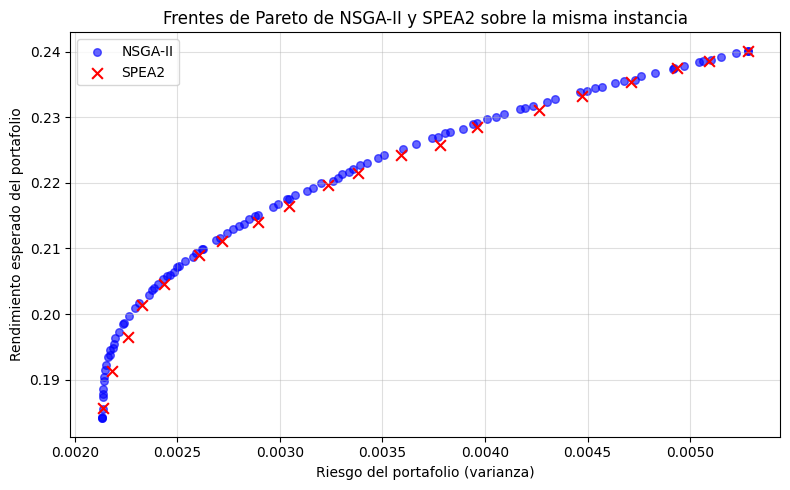

NSGA-II: 100 soluciones | riesgo [0.0021 - 0.0053] | rendimiento [0.1841 - 0.2401]
SPEA2: 20 soluciones | riesgo [0.0021 - 0.0053] | rendimiento [0.1856 - 0.2401]
Soluciones de SPEA2 dominadas por alguna de NSGA-II: 17 de 20


In [13]:
riesgo_nsga = np.array(pareto_risks)
rend_nsga = np.array(pareto_returns)
riesgo_spea = np.array([ind.objectives[1] for ind in pareto_front])
rend_spea = np.array([-ind.objectives[0] for ind in pareto_front])

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(riesgo_nsga, rend_nsga, c='blue', marker='o', s=30, alpha=0.6, label='NSGA-II')
ax.scatter(riesgo_spea, rend_spea, c='red', marker='x', s=60, label='SPEA2')
ax.set_xlabel('Riesgo del portafolio (varianza)')
ax.set_ylabel('Rendimiento esperado del portafolio')
ax.set_title('Frentes de Pareto de NSGA-II y SPEA2 sobre la misma instancia')
ax.legend()
ax.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

for nombre, riesgo, rend in [("NSGA-II", riesgo_nsga, rend_nsga), ("SPEA2", riesgo_spea, rend_spea)]:
    print(f"{nombre}: {len(riesgo)} soluciones | "
          f"riesgo [{riesgo.min():.4f} - {riesgo.max():.4f}] | "
          f"rendimiento [{rend.min():.4f} - {rend.max():.4f}]")

# Soluciones de SPEA2 dominadas por alguna solución de NSGA-II (menos riesgo y más rendimiento)
dominadas = sum(
    any(rn >= rs and qn <= qs and (rn > rs or qn < qs) for rn, qn in zip(rend_nsga, riesgo_nsga))
    for rs, qs in zip(rend_spea, riesgo_spea)
)
print(f"Soluciones de SPEA2 dominadas por alguna de NSGA-II: {dominadas} de {len(rend_spea)}")

Los dos frentes cubren el mismo rango de riesgo, desde el portafolio de mínima varianza hasta el de máximo rendimiento. NSGA-II entrega toda su población de 100 soluciones, mientras que SPEA2 entrega su archivo de 20, que el truncamiento reparte a lo largo del frente. En la mayor parte de la curva los puntos de SPEA2 quedan ligeramente por debajo de los de NSGA-II, y la última línea de la salida muestra que la mayoría de ellos está dominada por alguna solución de NSGA-II. La diferencia en rendimiento es pequeña frente al rango del frente, pero indica que en esta corrida SPEA2 convergió menos.

Esta figura no permite concluir que un algoritmo sea mejor que el otro, porque las dos implementaciones no son equivalentes. En SPEA2 la mutación se aplica, con probabilidad 0,1, a cada individuo, mientras que en NSGA-II se aplica con esa probabilidad a cada uno de los cinco pesos, así que en NSGA-II muta una fracción mayor de los hijos. Las poblaciones también son distintas, de 100 individuos en NSGA-II y de 80 en SPEA2. Para comparar los algoritmos con justicia habría que igualar los operadores y el número de evaluaciones, repetir las corridas con distintas semillas y medir la calidad de cada frente con un indicador, como el hipervolumen, que el código de NSGA-II menciona como extensión. El capítulo 16 trata la parte estadística de esa comparación.